In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
# importamos un dataset que ya viene en sklearn
from sklearn.datasets import load_iris
# separación de datos
from sklearn.model_selection import train_test_split

In [5]:
# k-vecinos cercanos
# primer modelo de aprendizaje
from sklearn.neighbors import KNeighborsClassifier

In [6]:
# metricas
from sklearn.metrics import confusion_matrix
# hace visualmente mejor a la matriz de confusión
from sklearn.metrics import ConfusionMatrixDisplay
#
from sklearn.metrics import classification_report

In [9]:
iris_dataset = load_iris()
iris_data = pd.DataFrame(data=iris_dataset.data, columns=iris_dataset.feature_names)
iris_data

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [14]:
iris_label = pd.DataFrame(data=iris_dataset.target, columns=["Target"])
iris_label

,Target
0,0
1,0
2,0
3,0
4,0
...,...
145,2
146,2
147,2
148,2


In [15]:
iris_data["target"] = iris_label.iloc[:,0]
iris_data

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [16]:
print("La clasificación corresponde a \n", 
      iris_dataset.target_names[0], ": 0 \n",
      iris_dataset.target_names[1], ": 1 \n",
      iris_dataset.target_names[2], ": 2 \n"
     )

La clasificación corresponde a 
 setosa : 0 
 versicolor : 1 
 virginica : 2 



# Preprocesamiento y entendimiento de datos

In [17]:
iris_data.head(5)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [18]:
iris_data.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [19]:
iris_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [21]:
print("Tamaño de filas y columnas de datos", iris_data.shape)

Tamaño de filas y columnas de datos (150, 5)


In [24]:
iris_label.value_counts()

Target
0         50
1         50
2         50
Name: count, dtype: int64

In [27]:
# ver si hay datos nulos, SIEMPRE VERIFICAR SI HAY DATOS NULL
print("Datos null, sin información: \n", iris_data.isnull().sum().sort_values(ascending=False))

Datos null, sin información: 
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


In [31]:
# ver correlacion
iris_data.corr()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
sepal length (cm),1.000000,-0.117570,0.871754,0.817941,0.782561
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126,-0.426658
petal length (cm),0.871754,-0.428440,1.000000,0.962865,0.949035
petal width (cm),0.817941,-0.366126,0.962865,1.000000,0.956547
target,0.782561,-0.426658,0.949035,0.956547,1.000000


<Axes: >

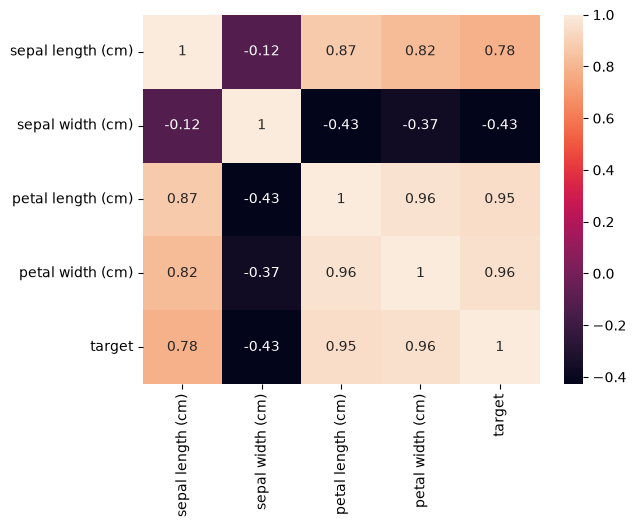

In [32]:
sns.heatmap(iris_data.corr(), annot=True)

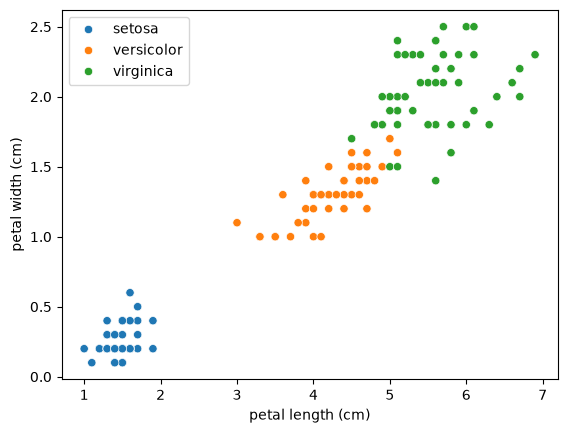

In [37]:
sns.scatterplot(iris_data, x="petal length (cm)", y="petal width (cm)", hue=iris_dataset.target_names[iris_data["target"]])
plt.show()

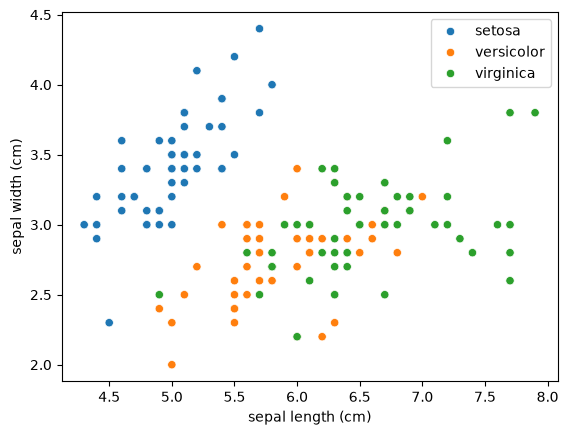

In [38]:
sns.scatterplot(iris_data, x="sepal length (cm)", y="sepal width (cm)", hue=iris_dataset.target_names[iris_data["target"]])
plt.show()

In [39]:
# vamos a separar nuestros datos 
# guardar en estas 4 variables
# vamos a poner datos de entrenamientos, datos de test (1° conjunto de datos)
# datos de etiquetas de entrenamientos y datos de etiquetas de test (2° conjunto de etiquetas)
# el primer parametro va para x_train, x_test
# el segundo parametro va para _train, y_test
# test_size el porcentaje de la cantidad de nuestros datos que damos para entrenar - re comiendo 70/30 o 80/20
# random_state es para que los datos sean mas aleatorios y homogeneos
x_train, x_test, y_train, y_test = train_test_split(iris_data.drop(columns="target"), iris_data["target"], test_size=0.3, random_state=123)

In [41]:
y_train

114    2
136    2
53     1
19     0
38     0
      ..
17     0
98     1
66     1
126    2
109    2
Name: target, Length: 105, dtype: int64

In [43]:
# declaramos nuestro modelo
knn = KNeighborsClassifier(n_neighbors=1)
knn

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None


In [45]:
# Entrenamos nuestro modelo
# pasamos nuestros datos de entrenamientos y nuestras etiquetas de entrenamiento
knn.fit(x_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [46]:
# Hacemos proyecciones
y_predict = knn.predict(x_test)

In [47]:
y_predict

array([2, 2, 2, 1, 0, 1, 1, 0, 0, 1, 2, 0, 1, 2, 2, 2, 0, 0, 1, 0, 0, 1,
       0, 2, 0, 0, 0, 2, 2, 0, 2, 1, 0, 0, 1, 1, 2, 0, 0, 1, 1, 0, 2, 2,
       2])

In [48]:
y_test

72     1
112    2
132    2
88     1
37     0
138    2
87     1
42     0
8      0
90     1
141    2
33     0
59     1
116    2
135    2
104    2
36     0
13     0
63     1
45     0
28     0
133    2
24     0
127    2
46     0
20     0
31     0
121    2
117    2
4      0
130    2
119    2
29     0
0      0
62     1
93     1
131    2
5      0
16     0
82     1
60     1
35     0
143    2
145    2
142    2
Name: target, dtype: int64

### Nuestra matriz de confusión nos dice que tenemos valores predichos y valores reales
Como vimos en el ejemplo anterior tenemos algunos errores

In [49]:
print(classification_report(y_test, y_predict, zero_division=0))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        18
           1       0.75      0.90      0.82        10
           2       0.93      0.82      0.88        17

    accuracy                           0.91        45
   macro avg       0.89      0.91      0.90        45
weighted avg       0.92      0.91      0.91        45



# Matriz de confusión

In [50]:
cm = confusion_matrix(
    y_true = y_test,
    y_pred = y_predict
)

In [51]:
cm

array([[18,  0,  0],
       [ 0,  9,  1],
       [ 0,  3, 14]])

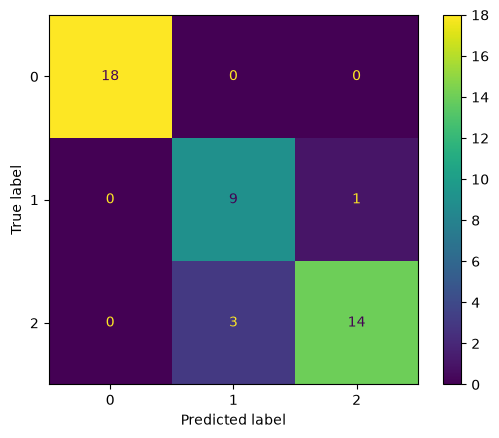

In [54]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()